# OCR для распознавания капчи
## Описание проекта
Решение финального задания по курсу **Deep Learning Basic**. Реализована модель архитектуры **CRNN** (Convolutional Recurrent Neural Network) для распознавания символов на изображениях капчи.

In [3]:
# Включаем автоматическое обновление измененных внешних .py модулей из папки utils
%load_ext autoreload
%autoreload 2

import os
import torch
import torch.nn as nn
import torch.optim as optim

# Импортируем всё строго из папки utils, как указано в структуре проекта
from utils import config
from utils.dataset import get_dataloaders
from utils.model import AdvancedCRNN
from utils.train import train_epoch, evaluate
from utils import show_worst_predictions, full_statistical_analysis

# Проверяем готовность вычислительного устройства
print(f"Вычислительное устройство: {config.DEVICE.type.upper()}")
print(f"Длина капчи в задании: {config.SEQ_LEN} символов")
print(f"Размер словаря классов: {config.NUM_CLASSES}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Вычислительное устройство: CPU
Длина капчи в задании: 5 символов
Размер словаря классов: 36


In [4]:
# Добавляем импорт из правильного места согласно структуре проекта
from utils.train import main

# Запускаем обучение вашей модели
if __name__ == '__main__':
    main()


[Train] Starting training process on device: CPU
[Train] Starting training for 20 epochs...
------------------------------------------------------------

Epoch 1/20


  Train Loss: 3.1152 | Train CER: 0.9255
  Val   Loss: 3.0086 | Val   CER: 0.9196 | Val Accuracy (Full Match): 0.00%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.9196)

Epoch 2/20


  Train Loss: 2.8624 | Train CER: 0.8895
  Val   Loss: 2.8258 | Val   CER: 0.9103 | Val Accuracy (Full Match): 0.00%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.9103)

Epoch 3/20


  Train Loss: 2.7296 | Train CER: 0.8848
  Val   Loss: 3.0845 | Val   CER: 0.9056 | Val Accuracy (Full Match): 0.00%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.9056)

Epoch 4/20


  Train Loss: 2.5954 | Train CER: 0.8603
  Val   Loss: 2.5310 | Val   CER: 0.8355 | Val Accuracy (Full Match): 0.00%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.8355)

Epoch 5/20


...

  Train Loss: 0.1160 | Train CER: 0.0350
  Val   Loss: 1.0801 | Val   CER: 0.3187 | Val Accuracy (Full Match): 20.09%

Epoch 17/20


  Train Loss: 0.0831 | Train CER: 0.0259
  Val   Loss: 0.5849 | Val   CER: 0.1664 | Val Accuracy (Full Match): 45.79%

Epoch 18/20


  Train Loss: 0.0805 | Train CER: 0.0262
  Val   Loss: 0.6636 | Val   CER: 0.2103 | Val Accuracy (Full Match): 33.64%

Epoch 19/20


  Train Loss: 0.0427 | Train CER: 0.0117
  Val   Loss: 0.2502 | Val   CER: 0.0766 | Val Accuracy (Full Match): 74.30%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.0766)

Epoch 20/20


  Train Loss: 0.0170 | Train CER: 0.0028
  Val   Loss: 0.2516 | Val   CER: 0.0710 | Val Accuracy (Full Match): 76.64%
  ✓ Saved best model to: weights\best_model.pth (Best CER: 0.0710)

[Train] Finished! Best Validation CER: 0.0710


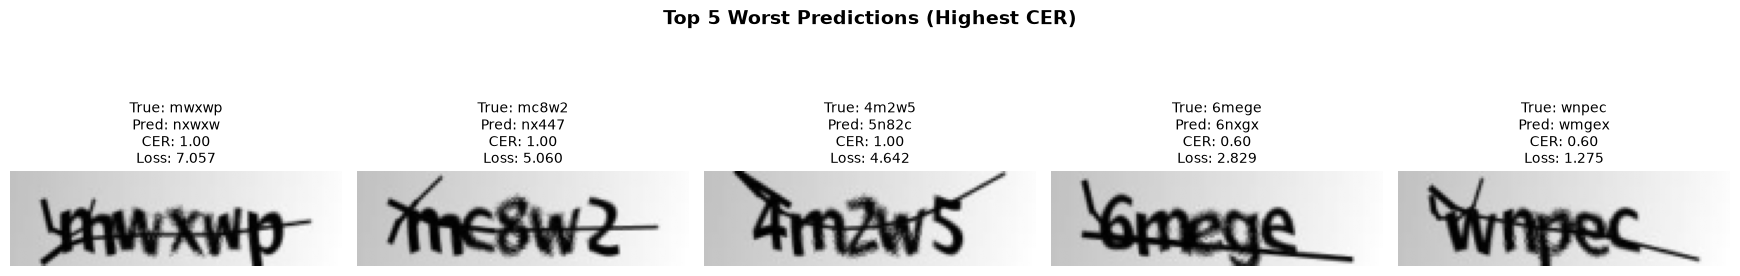

[Статистика] Всего картинок в тесте с ошибками: 50 из 214

Детальный разбор ТОП-5 худших предсказаний:
------------------------------------------------------------
Пример 1 | Истинный: 'mwxwp' | Предсказано: 'nxwxw' | CER: 1.00 | Loss: 7.0570
Пример 2 | Истинный: 'mc8w2' | Предсказано: 'nx447' | CER: 1.00 | Loss: 5.0597
Пример 3 | Истинный: '4m2w5' | Предсказано: '5n82c' | CER: 1.00 | Loss: 4.6423
Пример 4 | Истинный: '6mege' | Предсказано: '6nxgx' | CER: 0.60 | Loss: 2.8293
Пример 5 | Истинный: 'wnpec' | Предсказано: 'wmgex' | CER: 0.60 | Loss: 1.2746
------------------------------------------------------------

 Распределение ошибок по позициям в тексте (1-5 символы):
   Позиция 1: 7 ошиб(ок) (9.2%)
   Позиция 2: 14 ошиб(ок) (18.4%)
   Позиция 3: 23 ошиб(ок) (30.3%)
   Позиция 4: 19 ошиб(ок) (25.0%)
   Позиция 5: 13 ошиб(ок) (17.1%)

 Матрица путаницы — Топ-5 пар частых замещений:
   Истинный символ 'm' -> ошибочно предсказан как 'n': 21 раз(а)
   Истинный символ 'c' -> ошибочно пред

In [5]:
import torch
from utils import config
from utils.dataset import get_dataloaders
from utils.model import AdvancedCRNN
from utils import show_worst_predictions, full_statistical_analysis

# Получаем test_loader из функции
_, test_loader = get_dataloaders()

# Создаем модель для инференса и загружаем лучшие сохраненные веса
model = AdvancedCRNN(num_classes=config.NUM_CLASSES, seq_len=config.SEQ_LEN).to(config.DEVICE)
model.load_state_dict(torch.load(config.BEST_MODEL_PATH, map_location=config.DEVICE))

# Собираем ошибки и показываем топ-5 худших предсказаний
errors_data = show_worst_predictions(model, test_loader, top_n=5)

# Запускаем полный статистический анализ
full_statistical_analysis(errors_data)
